In [2]:
import os, hashlib
os.makedirs('/content/drive/MyDrive/QE_PhIm2SnCl6/07_gpu_t1', exist_ok=True)
S = r'''"""Wave-3 GPU: T1 (UKS triplet) relaxation of [SnCl6]2- (atoms 1-7 free, rest frozen) in the 11,077-charge ESP embedding,
starting from the relaxed S0 of gpu_s0_test.py. Then the four-point scheme:
E_S0(R_S0), E_T1(R_S0), E_T1(R_T1), E_S0(R_T1) -> vertical, emission, 0-0, reorganisation energies. Mulliken spin populations."""
import os, sys, json, time, warnings; warnings.filterwarnings("ignore")
import numpy as np, cupy
from pyscf import gto, lib
from gpu4pyscf import dft as gdft
from gpu4pyscf.qmmm.itrf import add_mm_charges
from pyscf.geomopt.geometric_solver import optimize
C = os.environ.get("CLUSTER", "/content/drive/MyDrive/QE_PhIm2SnCl6/03_cluster_tddft/cluster")
IN = sys.argv[1]; OUT = sys.argv[1] if len(sys.argv) < 3 else sys.argv[2]; XC = sys.argv[3] if len(sys.argv) > 3 else "camb3lyp"
NFREE = 7; HA2EV = 27.211386245988; lib.num_threads(8)
log = open(f"{OUT}/t1_log.txt", "a")
def say(*a):
    s = " ".join(str(x) for x in a); print(s, flush=True); log.write(s + "\n"); log.flush()
L = open(f"{C}/qm_cluster.xyz").read().split("\n")[2:55]
el = [l.split()[0] for l in L]
Xs0 = np.array([[float(v) for v in l.split()[1:4]] for l in open(f"{IN}/S0_relaxed.xyz").read().split("\n")[2:55]])
mm = np.loadtxt(f"{C}/mm_charges.txt")
def build(X, spin):
    return gto.M(atom=[(e, tuple(x)) for e, x in zip(el, X)], basis={"Sn": "def2-tzvp", "default": "def2-svp"},
                 ecp={"Sn": "def2-tzvp"}, charge=0, spin=spin, verbose=0, max_memory=60000)
def make_mf(mol):
    mf = (gdft.UKS if mol.spin else gdft.RKS)(mol, xc=XC).density_fit(); mf.grids.level = 3; mf.conv_tol = 1e-9; mf.max_cycle = 200
    return add_mm_charges(mf, mm[:, 1:], mm[:, 0], unit="Angstrom")
def spinpop(mol, mf):
    dm = mf.make_rdm1(); dm = [d.get() if hasattr(d, "get") else d for d in dm]
    s = mol.intor("int1e_ovlp"); ds = dm[0] - dm[1]; p = np.einsum("ij,ji->i", ds, s)
    q = np.array([p[p0:p1].sum() for (_, _, p0, p1) in mol.aoslice_by_atom()])
    return {"SnCl6": float(q[:7].sum()), "Sn": float(q[2]), "Cl_each": [round(float(x), 3) for x in q[[0, 1, 3, 4, 5, 6]]],
            "cations": float(q[7:47].sum()), "water": float(q[47:].sum())}
def energy(X, spin, tag):
    mol = build(X, spin); mf = make_mf(mol); e = mf.kernel()
    say(f"{tag}: E = {e:.8f} Eh  converged={mf.converged}")
    if spin:
        s2 = mf.spin_square()[0]; say(f"   <S^2> = {s2:.4f}  spin pops:", spinpop(mol, mf))
    return e, mol, mf
res = {}; t0 = time.time()
eS0S0, _, _ = energy(Xs0, 0, "S0 @ R_S0")
eT1S0, _, _ = energy(Xs0, 2, "T1 @ R_S0 (vertical)")
say(f"vertical S0->T1 (R_S0): {(eT1S0-eS0S0)*HA2EV:.3f} eV")
cons = f"{OUT}/freeze_t1.txt"; open(cons, "w").write(f"$freeze\nxyz {NFREE+1}-{len(el)}\n")
steps = []
def cb(envs): steps.append(float(envs["energy"])); say(f"  T1 opt step {len(steps):2d}: E = {envs['energy']:.8f}  ({(envs['energy']-eT1S0)*1000:+.3f} mEh vs T1@R_S0)")
mol_eq = optimize(make_mf(build(Xs0, 2)), maxsteps=60, constraints=cons, callback=cb, prefix=f"{OUT}/geomeTRIC_T1")
Xt1 = mol_eq.atom_coords(unit="Angstrom")
eT1T1, mT, fT = energy(Xt1, 2, "T1 @ R_T1")
eS0T1, _, _ = energy(Xt1, 0, "S0 @ R_T1")
sn = lambda X: [round(float(np.linalg.norm(X[i] - X[2])), 3) for i in (0, 1, 3, 4, 5, 6)]
say("Sn-Cl  S0:", sn(Xs0), " T1:", sn(Xt1))
with open(f"{OUT}/T1_relaxed.xyz", "w") as f:
    f.write(f"{len(el)}\nT1 relaxed (SnCl6 free), E={eT1T1:.8f}\n")
    for e, x in zip(el, Xt1): f.write(f"{e} {x[0]:.8f} {x[1]:.8f} {x[2]:.8f}\n")
r = dict(E_S0_RS0=eS0S0, E_T1_RS0=eT1S0, E_T1_RT1=eT1T1, E_S0_RT1=eS0T1,
         vertical_abs_eV=(eT1S0-eS0S0)*HA2EV, emission_eV=(eT1T1-eS0T1)*HA2EV, E00_eV=(eT1T1-eS0S0)*HA2EV,
         lambda_S0_eV=(eS0T1-eS0S0)*HA2EV, lambda_T1_eV=(eT1S0-eT1T1)*HA2EV, stokes_eV=(eT1S0-eS0S0-(eT1T1-eS0T1))*HA2EV,
         SnCl_S0=sn(Xs0), SnCl_T1=sn(Xt1), spinpop_T1=spinpop(mT, fT), steps=steps)
json.dump(r, open(f"{OUT}/t1_result.json", "w"), indent=1)
say("RESULT eV: vertical %.3f | emission %.3f | E00 %.3f | lambda_S0 %.3f | lambda_T1 %.3f | Stokes %.3f" % (r["vertical_abs_eV"], r["emission_eV"], r["E00_eV"], r["lambda_S0_eV"], r["lambda_T1_eV"], r["stokes_eV"]))
say(f"DONE in {time.time()-t0:.0f} s")
'''
assert hashlib.md5(S.encode()).hexdigest() == '5070ecb0324bbee9b2ba7c9ed563c6b1', 'payload corrupted'
open('/content/w3/gpu_t1.py','w').write(S)
os.environ['CUPY_GPU_MEMORY_LIMIT']=str(30*1024**3)
!python /content/w3/gpu_t1.py /content/drive/MyDrive/QE_PhIm2SnCl6/06_gpu_s0_test /content/drive/MyDrive/QE_PhIm2SnCl6/07_gpu_t1 camb3lyp 2>&1 | grep -v -i warn


S0 @ R_S0: E = -4042.53125108 Eh  converged=True
T1 @ R_S0 (vertical): E = -4042.40309866 Eh  converged=True
   <S^2> = 2.0360  spin pops: {'SnCl6': 0.0009797907191177464, 'Sn': 0.0007948766689946259, 'Cl_each': [0.001, 0.0, 0.0, -0.001, 0.0, 0.0], 'cations': 1.998975934084597, 'water': 4.427519622054309e-05}
vertical S0->T1 (R_S0): 3.487 eV
geometric-optimize called with the following command line:
/content/w3/gpu_t1.py /content/drive/MyDrive/QE_PhIm2SnCl6/06_gpu_s0_test /content/drive/MyDrive/QE_PhIm2SnCl6/07_gpu_t1 camb3lyp

                                        ())))))))))))))))/                     
                                    ())))))))))))))))))))))))),                
                                *)))))))))))))))))))))))))))))))))             
                        #,    ()))))))))/                .)))))))))),          
                      #%%%%,  ())))))                        .))))))))*        
                      *%%%%%%,  ))              ..              ,)

In [2]:
# 1. 检查 GPU 并挂载 Google Drive
!nvidia-smi
!nproc; free -g | head -2; df -h /content | tail -1
from google.colab import drive
drive.mount('/content/drive')

Sat Oct 24 03:59:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             44W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

ValueError: mount failed

In [ ]:
# 补丁：TDDFT 显存回退 + 限制 gpu4pyscf 显存 20 GB；然后后台重跑任务 B
import base64, io, tarfile, hashlib
d = base64.b64decode('/Td6WFoAAATm1rRGAgAhARwAAAAQz1jM4E//EeRdADkdSf9bfqww1ITe2rM8+emfmkL81JhfMb4tPW6v5UuPSz+mHfpOy9Ic048TYNhnidcIstr1P+3mdiBP19GTtaFajuBM0hptKfJtQoBE4hw+slbcyi00VikvozUW2/fEa+noCsdwfc6aXvgLLzAbJ0K0BfdFBPIJrE0CAd3VEqAFBx7GdW0abFmD3oQij20HNvis9yW7KwvfWbRGtepIefcZxC8u0zdJTvHRww295s3d921oSbYyBRosZvT7PFaajvaHY3WbqVse45kiOveXwmHrZv5kLpqC9AinWo/sYztD+5JrJlHYfI/QVVjwgk6wV18g1BQI14/YDv2qikR2ZwdIKK9HMmtKJL5hflfU877kNeUBD1hT5f2Dvh7fa9ZY/h5hv6M/SxXmFghnDHYzN7eXUgXkRaDQ062XapQzlIkfqRQ34lB+IHlA5a2m5H2owVvKVgNs/IdZ34kKYPJIdT9K6BO7VNKzzCh8ahSadTJYsgrMOYc/IQoOPX+GRIeNFEPFH6duHhlI7JwPUcsPwwUUtAPrr5b3dlyPWAZQMn3+Pq73bamQ9ZRlXUSS5B3AT5th/OQmF3V3MvRrncgP5q36qkcKdpX2OJWgsq/lpkxtNuhguwVdPX0Ja/ptIpDFBi32U/rscTro11O7VC+CHeWJd4JpNPpN7nhSxoWIQeRIJLWKFL3YppuJjZGc9G4aZL5lGoW/sgh9vauTS8t5h3ocEuwutMJxqUzKb6K/j/aHjKNykrNUO+sGVr7ruIPQLt9dMbzgDMMjMnX7zjkyhVzq8z2Ty0JqUBH+g9LVLpGJlVmpBgWXS8ZQ4Oe2ZcuQ88lrsOA8KdhKTntGGUAgE8h8+j+TklE+CQipo7IrFUrAy27331M8LdDzHHXqSw+q/poOu5CJ1LUl3MMckKN9w5qNkEgKlwJTki2YzCAQdw4RYeZ1ZygeEuyT/Moc7sCWPq19X/qMG3mV+quNCkhMJKPSD9krC5CMNSzOtxA/RGSBtFH53682QZqcrR1uDhAwYw7zIQAxkBNFnNQFQ+8I/1qgbaWIZXzhTGQpJp2hna3u8SSIOXbgwfmCqP3bj04wImCuctYrgSa7eV/fjpqDxk4IIFQQtVJt139ENV/ZiDn9Xioopi84elB7zYnqKYRtbiPNzULylRpLEDINICOceU+uy/GT6ldcq2jzjfabG3RWnEXKUe0pF4fG7pAR71nhuKlHz+P/6UnlW3eIQ+1hyd/vU0ENJca5GyCBJq1UyqH6hUPegG+FyZsFYHqFQnKv46Y67puiLyC0Oz6hOGRDhGKjqKz+mZ1AeqHe31Xb4BqqoNHTBPUbrjiFtBnlDmXi071SGtjEFqadoIvfpsarHt24aMcg3H0jRDFtVb2f5OCJLr4WG3UGi3XEwSxINvV8sAyiRvRwrvGwpnSRbWXVgU/VzqE/OIuJueS3/9yoeYFIH4Yqmt55IfvccqfIySeI1a/5UB6J4nmU9nEjEAkJpA3IwY9kmMIHjLcDdV7GHHeZY05R2NsDa/t0c14Jl37pJUksz8NIjpU8ul282hYlMUvD+q+5mBK9CAZPNoiS281CVutpkt9JX9GGCSTYa51DOPjcReO2c0ufEP6ANYudhnVTVddqATmvLDXybagaiScMpGkdX/beskBIjqJ0ohIWzpbt+mKxGM6i0Fp74mCQ71kpEKJhecGWyERYoH5JWpelZUoeNJGVGiAyRH2fIt+JaeWPsi846szB2CpXJ1K3ACElpoGVXXXE15P5TFYxomCSQ/Y9N+6KrKnYMpIqqDHoLvZ7zS/00osVnbCkoUlq9gUG6SZ84BsE4wQF1mUcEj/ZEk9Jbr+h+L0yitnDzWNNaL1rhupdmR/gNnsQ5bjRqzdtTXjfs4OndJhNLaJvu7w6O0L75lvSG9TvBnu5QBDfXXHh7y9emwbVfwebhU6bsDWRHXBi7MWMjploRcHLupkhobc6rZBjudww5Gvggh/pp4kdw+CmXxO8nswYhjmmbAlRfZ/5O+XQyLO9SdtoC1TKlT/eHathBuVMoryV8vt5kYnSVHAhSKRz4jUkSBWVxc/Xys91JIRhDmbwgfCwyFNjj9XFcfxUzn8NrSjLFLnyT5p+p67m1vmbvTv/fQMxUdtJZLlNsJt3BVUfHcSkpMpt4bla+cLMZ3QpsQE/9V1p4N7qHC5jjB2O3LjGc8bWKdQ2NeCM44kb5JG6oE+VCt/EVSeks0lUTAouQqqHMpT0lwCBGNOr0yUEXKNo0oER0HbVefSnVbqHTotHtEDTRH/N4xm74oGfaHb79aUSjY1VYEaeLAVMjq8jM9SsDgkLyPivS66NcqzXy14JiTrXsgWY4A2UoxOrwaqPrJeA7zwxv65Un8BBL/9SkB0U+YBKH9J7BlVenUIEqfHFOkxATu2IYa2MmonR8PRWZksZlN36gtsvk1sJ4ADEYmJCCqnDuphife3q56zdkRSnc0tZ9/ic15fJb4rD50eLbS+93E+l/lSrws2cORTWo+l7/kfsiBXxN1l9gPDl2Bj23vsawbI7/c6idPsyzBsW4yQ4DqgvEGKf2iNMf9lbWnMor6JTmyrtA3kcnbzscWOZ/mbYUCmvaHZ6Vgs3y+8Ki8Xe7E5jNXF4hcG5E8jdtP1P2sFAmctId1Ri6mD6cXbKyYIuvGP7qoTI5cfD3HUIre3sp5MPmmSHd/kFj+HJVOe11+qkhm/6D4qPpoJMTjP+gnMq06UsD/cNsYUr34kRPYkA+apsLUihYS5kqKnY1tbK86jF6W9aRw9UrWvLYLeG9jEAaEr+kZd8MBS7st3LsyIAbh2FkFPlg9C9VeK9NjzS3uUznIqm8zhZ5/7ahuRqZCyd82M7xCjXYt4twb4SZ5HHZO4gdmWeVdenz1Yfxu84DYOgCMGUP/qG9cB722Uvi6JOEyGT1KybrU+arKSAjbfqqXYt/ezTLk4tbAiFV71SrxJyJ8j4F/z0dzAUVl2ZW8hwqjccNFuhUzwRuNRNPggL6aHzRgl9dKZOPFuGs34+l4YYCTPI8zLSEZLsFAf6FjYfu/59HEHcabp83nVD2dbjaZrctu3uAD5QqV3cDUYQzC+Qvc6SssClz0ZXMwpZ71g7jvFYRr7AmV4JRm+2WQKuDk1ngcEkpQBa0T0dyY2G2sUkpcp2daZHYsIdbX0vM9HRHvdjwz0Ej7hw+Mm3ngZbHOVS1xK0iEUfFYFSsdZ6/dagBpWfRYwcwZmlHEumzvyH6kmYYi4d0XV9Xsa8INhmDQG22J4BW6kIvI7Rl+oDtmwCi/nPC1d32CD5WDtn9df29RDv+Nm+an5DfmtaNgHH39vNN30WzLqthqWDy0dNOH+stjuGpf/+9czDsydFbUndpO2K/Xv64IHF+LBHZ8r5Nya2BvybjZsKWu1psxuMcs3oRDotavelLuT/GVxZMZiWWMtk4Ct6nYU3BJCaM+XKpI4WVLjGwXqyCSfsYhF66BajJK25+oWrXwz0NeMWoarnQajFP0KotEjRiQC4c4GBdHHeGOLFZmqvDExBXiAYKY3Pi2xXO8zHBRc0jYcUrsNOjwDSCQkWW8s00Qzyr9uVSnXPnnW3NrCsryNzJnvtMXzVMWC01DbAt7YPn8cH6naTdV8txIUNedboYNekVdMm1maBck7VIiIY9mtHpt2cly4OAv0x+MLdyMIaNvb7DFc1Pgq/5aX8pgRnkUzVTWR17eh98+pI+8P2ihQCkK64qUihwWakIT50W6ruAWxuaQF3oC7pHN6cbNMjkddwicbxWFssgV0mnemZd4VCDqrpJAV2PghqFoY3YqLngOLBvu/CfRGqTSYrIfTjdm/8ycBkXm6MwAwDKwfkU89qdvmzHWHd2PrWG8VL6WQ9nAQmRqCH6Tx6B0IiNINFLixlOe6sc+hSnkXuKMAJDVRbxRlqpUh0gvvgotb3tIhK4xhVfVH5NZmep7u+mxVFMEqwj/13kUkn+Rmaufa/ZDtbQARo8wJSJBvl4o0MVxGpgio4atNBNNrjoTbcPNGOB1nWuYfz8R7lb4qPsp/DH+/jy66YfTZU24o8XbjjZvemIqdsytGcC9laie5SdWKddIS3ksSaWF91fHaP6CTHt1wPYpAEhtlxlMCnk7qCyAcTOPi/byMBHE2N2lsqiizig0F2Pse6DdGa4wEbdhWeGjrpqA+xSDYCMr9ueFQVeSucMaz7UYvcv8fyYllHDDEs8qcA2Oei6qy4J/DYQ2XxEEcB4yRLbvtIR0s8HEibSyCa8+OU/FRaOIZPrANZLEf9WHV7fyxh+X35bSsubb/nB9gE7nlFcHwKka8eIykZBvekf+jLgJ3XzErJlLZa5Gy+tvOeFammfYIIGkxRn/3JzOq+WcDKdm1yulD03gP68g+fV/+qa1f64l8i6RRUqil6uJYJTcXGYIDPTh8bhndixcRfCYzaGmVIq99o5XUJJm78Nq/ZlvHQzfa3AmMQZgqFlpTZK+Ltj6Q0enLFjS5klitlhCR2CXzUc14PVOjTrX2nxQV5HpRpGuUhT3mWX2AH4nhlXJCndUfFL1+wtgeFIhKvT1i07wxlOi8yaTvcCYf2rlg0jLMnbecjyV9DX5aeX9cFm1oDKKtiekowBV7Lj6EDZ1XirLzv6xPN1rYPHRAkB1K9o7FiENzwY/BMx/K/nxbfFL7/MbCD8GLf4yrZ/JiyHcWToP3RNum7mpxrYGGql6xMjZxrcEp0RbIiRPvO8o6OLnsp3U5epLqTsOYXHSAwohXv4RYm0Xon6IqaSvI8+T5cXXD3XoBneYpLbiFMyT5kDVsH+dcYA45OHcOnLnmT9f6/XtrpiEpuWqKXb4MYXdNtJG43twhfI0AF+vYzhRgY4wiDtoqhnXk9tvlY97BS/SvR33Ouf1gcWBi3uZBfFa0rQEJDhUUDPMj2tQtgC/G+OYU+l0BoOgF7KPOX7/irXn4F9/ld9SJr69fyOh4c2Rr+DxGfh9Biadk2g6B7wx54xVYxVNw4ZIxTwtrf+KbVzmoOAktpQbOfETYstvAqmF1jdBUY3BMLvSAwDdhuffgTncegneEhhWCaJCcjArLOYP/8LtAAl/sQxc+hfBDeufNTT2Dtb9bm5FwPmolo1fRe0bDAVBM8j68HqAZ3qtDqjSQZ/KMogOoGcMXrunfBGMNI2nF2P3BPVZTlPqZSu014/b83Obr2hyQD1RPfTxE5Azd4toWYg5z4nKvmKVaq8Xap1mf/uoIQCgEN6mq8gOm1fQY+w7zTOFE2C3R/5+1OJG0aJW4+XRHI3fBD3pNYbw3O/Z+omhL+RdoiPve5e9M7laBgvQF7mor6Fc7Cepu0a0/E432gaL//RQ6GixTutbuG7gVq0VbDnKXD5r2DmdHCH6iUEuUXvO9Edc861szL6kh749bk/fopNS7e9TN+XsEiyy2RQRGAm2R9YTTENrLxNJd72bQWeOnjQvgR5e0fvXLxkN3/0lHOsY90eE9ax/nbu3DRzFm3AVw3+EnXpQBMf18JAPCdyjR8nrscGeXAE1gpTceDXznLbjHWw10Fbkqm9YHA86Qf4hisROGMRzhzVYWI1Psf09rhR2ab8DKg0ogmCFgYeHZlYAIsjETChhyHQZTPzh5kpbFh22ViV6geC4uWg+KzLQzff8sckl+jh+kEiZlJydYch8nD+wMLoLcJzqGZYY/OSqgZIgzW4O8L+96tnJG/zpzPKNNyBd7l0FwU0JiVzRJhmLbfOzf/KNuDEIdF2bZw8QyGsDzpe5kTpMSxulCJNWOOLzlWp9IlcWtBvzXcSXjwLks0hCUtM6XeC0i4+o6gilm+0s+VIn+pKH+oklgCeJFUvLFIhWGZJa6nZMWispslqP2KZ6utaGpPPfJncD4xVxfxhQviaz0UiGZIFT3h64H4bvn1qiB+YifwwJtE3FclkJf/wJ2hL1w3XOywT8WQRW3s38GcWFbvUQYhR4jToChBPH1dsC1ACnuMZHMqMqcZ/3ijg0Fcqum2M7rL1cObvn7PwqVCMqSNDgP148p7rBNy1HZNUdV1qY2wKYxPFT5FcKlQern/Qg90U3VVuP6FJtLC4yEGzxkBVDoeUxuDpcPGf1spLNJZ7khiYvkBxubanGgAAA/PowV2bKLsAAGAJICgAQDbk57EscRn+wIAAAAABFla')
assert hashlib.md5(d).hexdigest() == '3a6ed653487e7ec4d8e5024331e41b08'
tarfile.open(fileobj=io.BytesIO(d), mode='r:xz').extractall('/content/inputs')
!grep -n 'CUPY_GPU' /content/inputs/run_cluster.sh
!nohup bash /content/inputs/run_cluster.sh > /content/drive/MyDrive/QE_PhIm2SnCl6/wave1_logs/taskB_tddft.log 2>&1 &
!sleep 5; tail -3 /content/drive/MyDrive/QE_PhIm2SnCl6/wave1_logs/taskB_tddft.log

10:export CUPY_GPU_MEMORY_LIMIT=$((20*1024*1024*1024))   # cap gpu4pyscf at 20 GB so QE can share the A100


/tmp/ipykernel_5047/1912381950.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tarfile.open(fileobj=io.BytesIO(d), mode='r:xz').extractall('/content/inputs')


/usr/local/lib/python3.13/dist-packages/gpu4pyscf/lib/cutensor.py:154: UserWarning: using cupy as the tensor contraction engine.
  warnings.warn(f'using {contract_engine} as the tensor contraction engine.')
gpu4pyscf 1.9.0 pyscf 2.14.0 cupy 14.2.0


pdos.png written


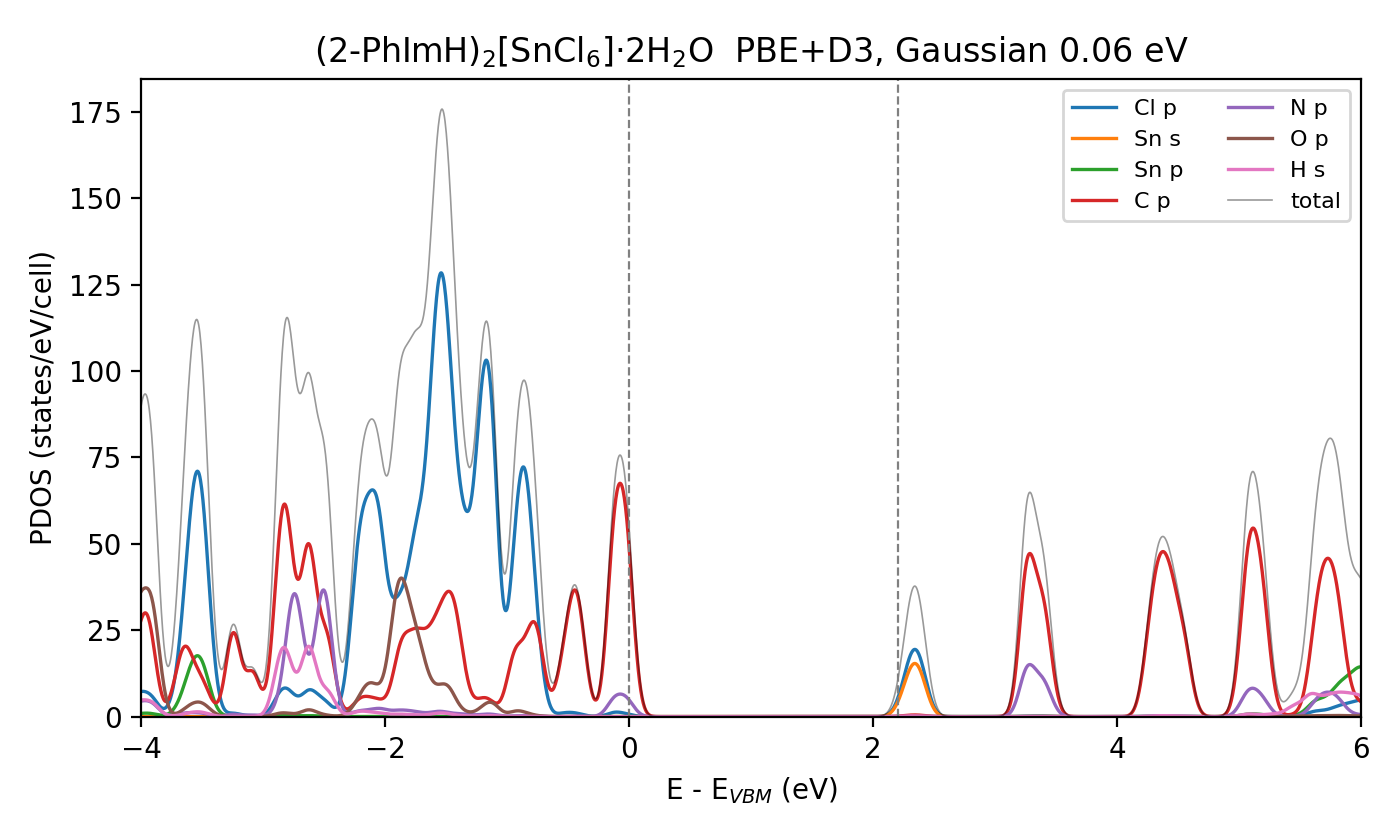

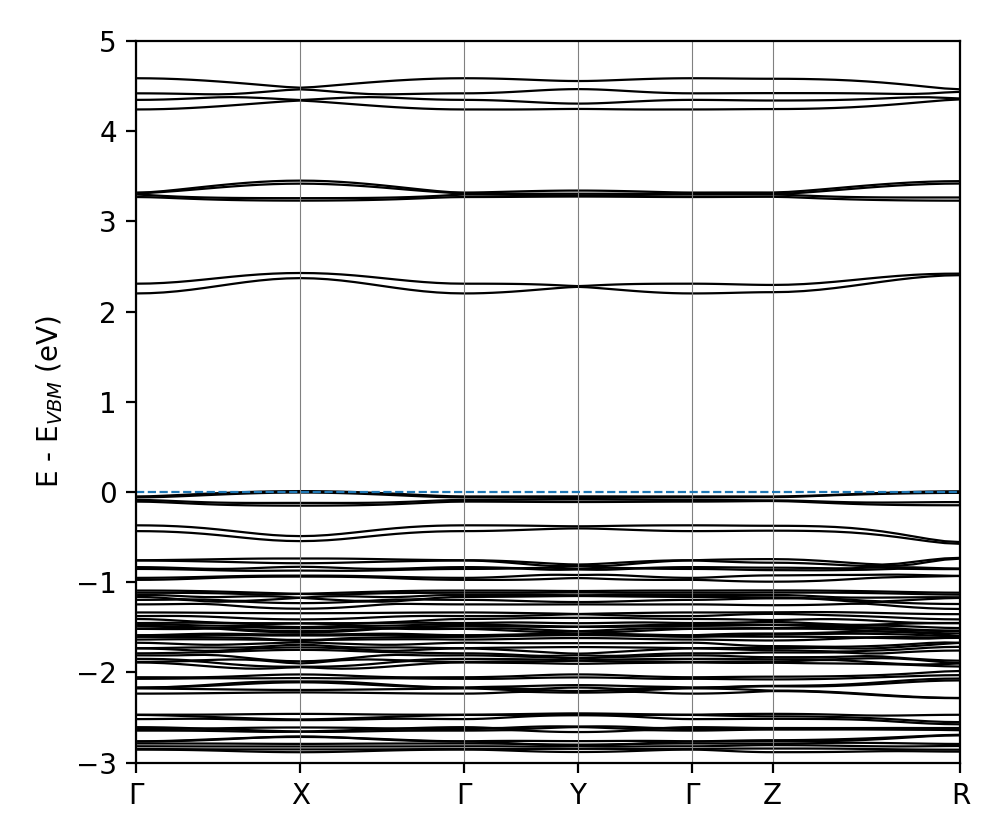

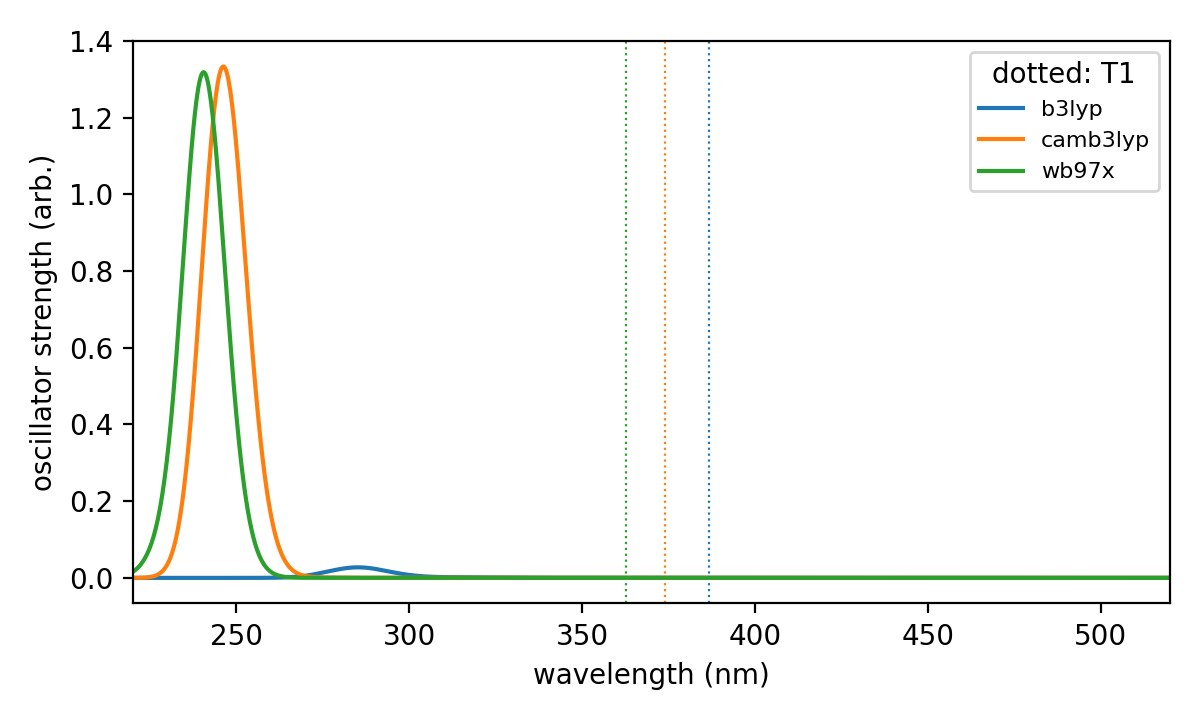

In [ ]:
# PDOS 改用投影系数 + 高斯展宽重画（projwfc 的优化四面体 DOS 输出为 0）
open('/content/inputs/pdos_from_proj.py','w').write(r'''import re, sys, numpy as np
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
W = sys.argv[1]; VBM = float(sys.argv[2]); GAP = float(sys.argv[3])
st = re.findall(r"state #\s*(\d+): atom\s+(\d+) \((\w+)\s*\).*?\(l=(\d)", open(f"{W}/projwfc.out").read())
key = {int(i): (e, "spdf"[int(l)]) for i, a, e, l in st}
x = open(f"{W}/tmp/phim_sncl6.save/atomic_proj.xml").read()
RY = 13.605693122994
E = np.linspace(VBM - 6, VBM + 7, 2601); sig = 0.06
pd = {}; tot = np.zeros_like(E)
for blk in re.split(r"<K-POINT", x)[1:]:
    w = float(re.search(r'Weight="([-\d.Ee+]+)"', blk).group(1))
    eig = np.array(re.search(r"<E>(.*?)</E>", blk, re.S).group(1).split(), float) * RY
    g = np.exp(-(E[None, :] - eig[:, None]) ** 2 / (2 * sig ** 2)) / (sig * np.sqrt(2 * np.pi))
    tot += 2 * w * g.sum(0)
    for m in re.finditer(r'<ATOMIC_WFC index="(\d+)"[^>]*>(.*?)</ATOMIC_WFC>', blk, re.S):
        v = np.array(m.group(2).split(), float).reshape(-1, 2); c2 = (v ** 2).sum(1)
        k = key[int(m.group(1))]; pd[k] = pd.get(k, 0) + 2 * w * (c2 @ g)
Er = E - VBM
fig, ax = plt.subplots(figsize=(7, 4.2))
for k in [("Cl", "p"), ("Sn", "s"), ("Sn", "p"), ("C", "p"), ("N", "p"), ("O", "p"), ("H", "s")]:
    if k in pd: ax.plot(Er, pd[k], lw=1.2, label=f"{k[0]} {k[1]}")
ax.plot(Er, tot, c="k", lw=0.6, alpha=0.4, label="total")
ax.axvline(0, ls="--", c="gray", lw=0.8); ax.axvline(GAP, ls="--", c="gray", lw=0.8)
ax.set_xlim(-4, 6); ax.set_ylim(0, None); ax.legend(fontsize=8, ncol=2)
ax.set_xlabel("E - E$_{VBM}$ (eV)"); ax.set_ylabel("PDOS (states/eV/cell)")
ax.set_title("(2-PhImH)$_2$[SnCl$_6$]·2H$_2$O  PBE+D3, Gaussian 0.06 eV")
fig.tight_layout(); fig.savefig(f"{W}/pdos.png", dpi=200)
np.savetxt(f"{W}/pdos_by_element.dat", np.column_stack([Er, tot] + [pd[k] for k in sorted(pd)]),
           header="E-EVBM total " + " ".join(f"{a}-{b}" for a, b in sorted(pd)), fmt="%.5f")
print("pdos.png written")
''')
!python3 /content/inputs/pdos_from_proj.py /content/work_02_bands 0.950 2.201 && cp /content/work_02_bands/pdos.png /content/work_02_bands/pdos_by_element.dat /content/inputs/edge_comp.py /content/inputs/pdos_from_proj.py /content/drive/MyDrive/QE_PhIm2SnCl6/02_bands_pdos/
from IPython.display import Image, display
P='/content/drive/MyDrive/QE_PhIm2SnCl6'
for f in ['02_bands_pdos/pdos.png','02_bands_pdos/bands.png','03_cluster_tddft/tddft/absorption_tddft.png']:
    display(Image(filename=f'{P}/{f}', width=560))

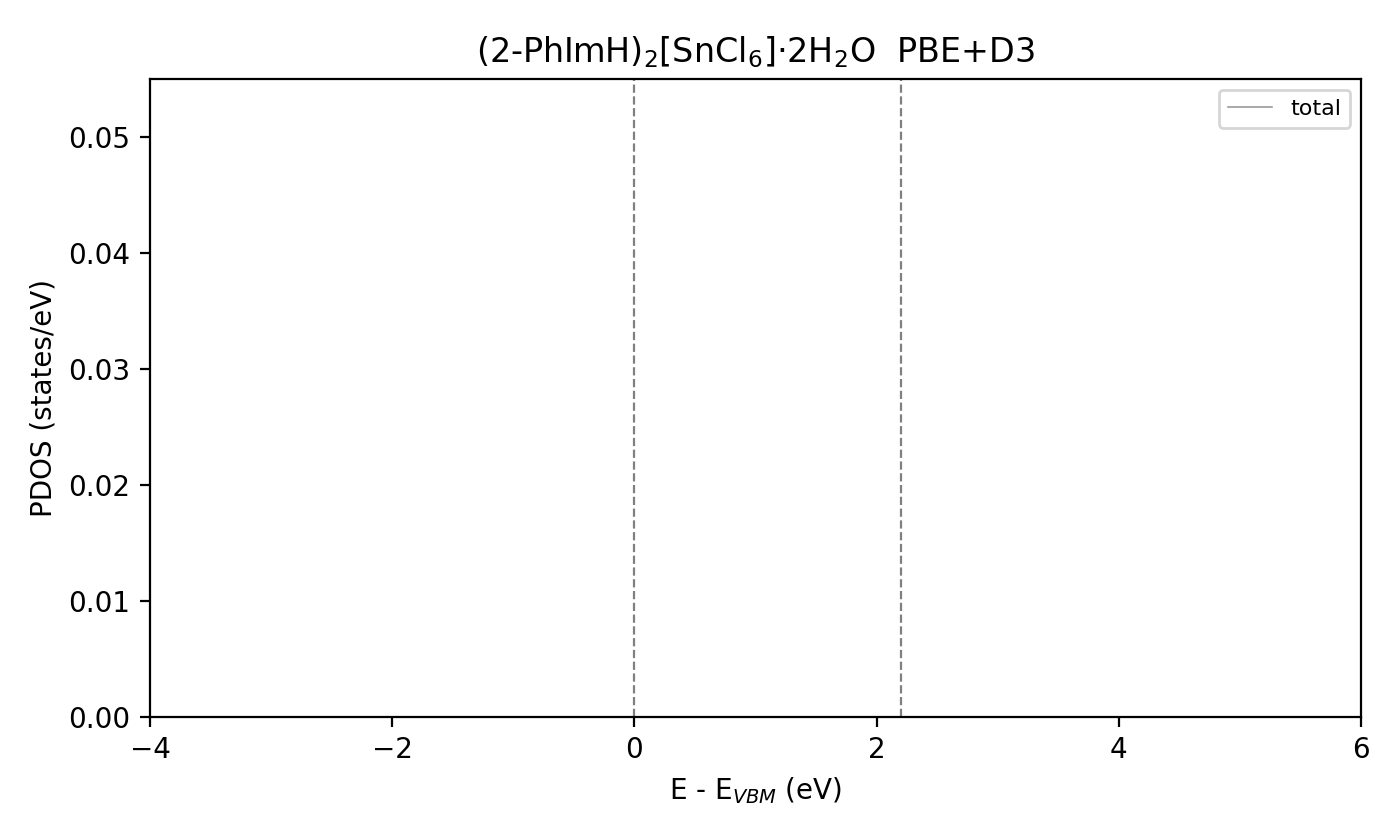

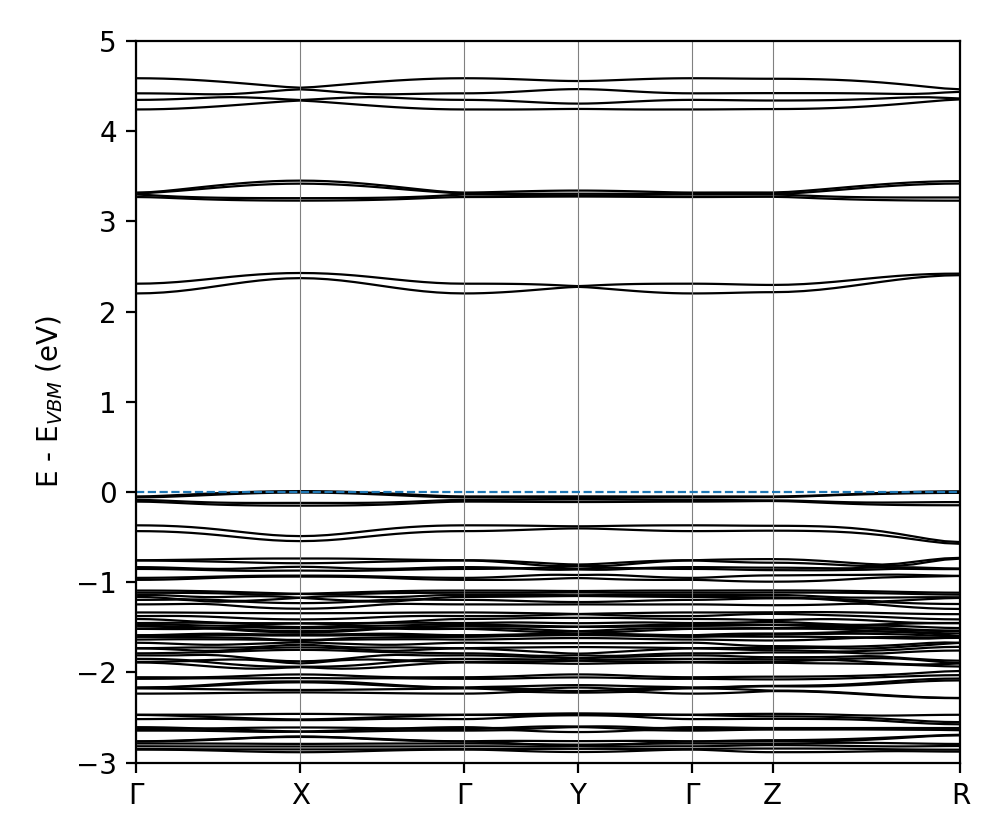

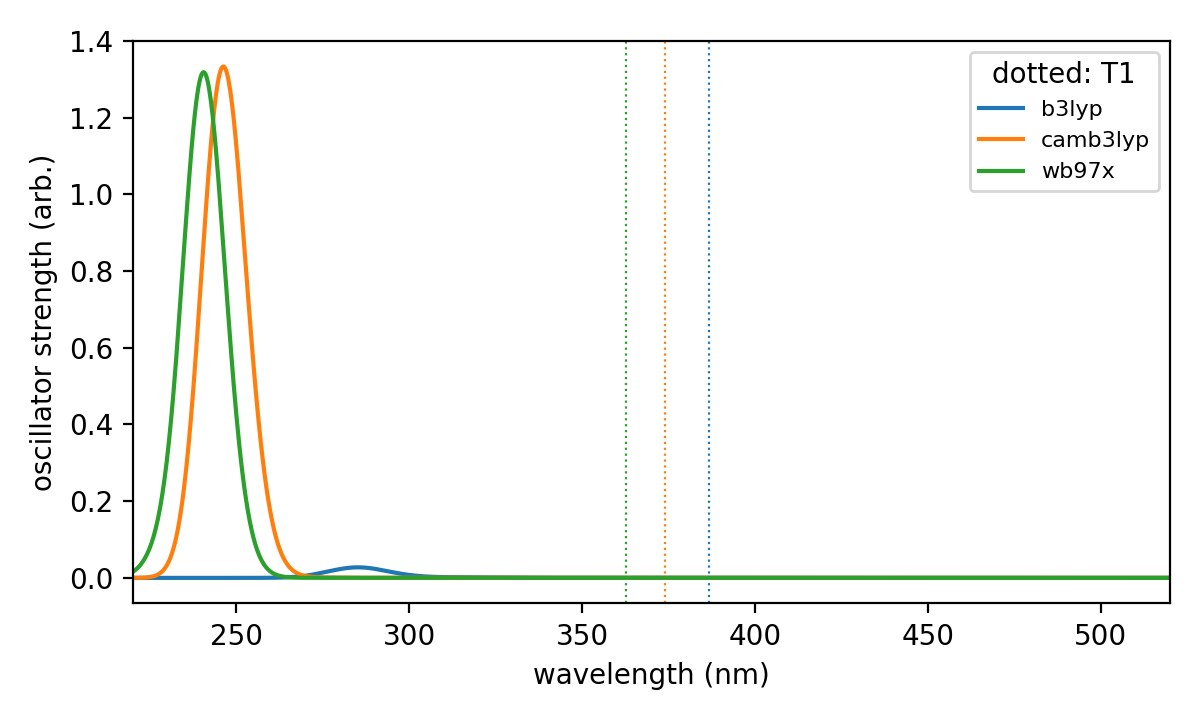

In [ ]:
# 第1批结果图
from IPython.display import Image, display
P='/content/drive/MyDrive/QE_PhIm2SnCl6'
for f in ['02_bands_pdos/pdos.png','02_bands_pdos/bands.png','03_cluster_tddft/tddft/absorption_tddft.png']:
    display(Image(filename=f'{P}/{f}', width=560))

In [ ]:
# 5. 分析结果（能量、受力、键长、与实验结构偏差、收敛曲线）
!python3 /content/inputs/analyze_relax.py